<a href="https://colab.research.google.com/github/sim07hamdani/FDM5-3P-Travaux/blob/main/notebooks/06_sympy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aelkharrim/FDM5-3P/blob/main/notebooks/06_sympy.ipynb)

# Python pour la physique — 6. SymPy : les mathématiques symboliques

> 💡 **Astuce**
>
> **Rappel** : exécutez les cellules dans l'ordre avec **Maj + Entrée**. Les solutions des exercices sont masquées dans des cellules « Solution » : essayez d'abord par vous-même !



> **Objectifs**
>
>
> 1. Évaluer des expressions avec une précision arbitraire.
> 2. Effectuer des manipulations algébriques sur des expressions symboliques.
> 3. Effectuer des tâches de base de calcul différentiel et intégral (limites, dérivation, intégration) sur des expressions symboliques.
> 4. Résoudre des équations polynomiales et transcendantes.
> 5. Résoudre certaines équations différentielles.


**Qu'est-ce que SymPy ?** SymPy est une bibliothèque Python de mathématiques symboliques. Elle vise à être une alternative à des systèmes comme Mathematica ou Maple, tout en gardant un code aussi simple que possible et facilement extensible. SymPy est entièrement écrit en Python et ne nécessite aucune bibliothèque externe.

La documentation de SymPy est disponible sur <https://www.sympy.org/>.


> 📝 **Note**
>
> **Calcul symbolique ou numérique ?** Avec NumPy et SciPy, on calcule avec des **nombres** (approchés). Avec SymPy, on calcule avec des **expressions exactes** : $\sqrt{2}$ reste $\sqrt{2}$, la dérivée de $\sin x$ est $\cos x$. Les deux approches sont complémentaires : on trouve souvent une formule avec SymPy, puis on la tabule avec NumPy.

In [163]:
# Cellule de préparation (facultative) : exécutez-la une fois au début.
# Sur Google Colab, NumPy, SciPy, Matplotlib et SymPy sont déjà installés.
import sys
EN_COLAB = 'google.colab' in sys.modules
print('Exécution dans Google Colab' if EN_COLAB else 'Exécution en local')

Exécution dans Google Colab


# Premiers pas avec SymPy

## SymPy comme calculatrice

SymPy définit trois types numériques : `Real`, `Rational` et `Integer`.

La classe `Rational` représente un nombre rationnel comme un couple de deux entiers : le numérateur et le dénominateur. Ainsi `Rational(1, 2)` représente 1/2, `Rational(5, 2)` représente 5/2, etc. :

In [164]:
import sympy as sym
a = sym.Rational(1, 2)

In [165]:
a

1/2

In [166]:
a*2

1

Pour que les résultats s'affichent en jolies formules mathématiques, activons l'affichage amélioré :

In [167]:
sym.init_printing()

SymPy utilise `mpmath` en arrière-plan, ce qui permet d'effectuer des calculs en arithmétique à précision arbitraire. Ainsi, certaines constantes spéciales comme $e$, $\pi$, $\infty$ sont traitées comme des symboles et peuvent être évaluées avec une précision arbitraire :

In [168]:
sym.pi**2

 2
π 

In [169]:
sym.pi.evalf()

3.14159265358979

In [170]:
(sym.pi + sym.exp(1)).evalf()

5.85987448204884

Comme vous le voyez, `evalf` évalue l'expression sous forme de nombre flottant.

Il existe aussi une classe représentant l'infini mathématique, appelée `oo` :

In [171]:
sym.oo > 99999

True

In [172]:
sym.oo + 1

∞

> **Exercice**
>
> 1. Calculez $\sqrt{2}$ avec 100 décimales.
> 2. Calculez $1/2 + 1/3$ en arithmétique rationnelle.

In [178]:
from sympy import sqrt, N, Rational

print(N(sqrt(2), 100))
print(Rational(1, 2) + Rational(1, 3))

1.414213562373095048801688724209698078569671875376948073176679737990732478462107038850387534327641573
5/6


In [174]:
#@title Solution { display-mode: "form" }
print(sym.sqrt(2).evalf(100))
print(sym.Rational(1, 2) + sym.Rational(1, 3))

1.414213562373095048801688724209698078569671875376948073176679737990732478462107038850387534327641573
5/6


## Symboles

Contrairement à d'autres systèmes de calcul formel, avec SymPy il faut déclarer explicitement les variables symboliques :

In [179]:
x = sym.Symbol('x')
y = sym.Symbol('y')

On peut ensuite les manipuler :

In [180]:
x + y + x - y

2⋅x

In [181]:
(x + y) ** 2

       2
(x + y) 

Les symboles se manipulent avec certains opérateurs Python : `+`, `-`, `*`, `**` (arithmétique), `&`, `|`, `~`, `>>`, `<<` (booléens).


> 💡 **Astuce**
>
> On peut déclarer plusieurs symboles d'un coup : `x, y, z = sym.symbols('x y z')`. En physique, on ajoute souvent des conditions, par exemple `m = sym.Symbol('m', positive=True)` pour indiquer que la masse est positive, ce qui aide SymPy à simplifier.

# Manipulations algébriques

SymPy sait effectuer de puissantes manipulations algébriques. Regardons les plus fréquentes : `expand` et `simplify`.

## Développer (`expand`)

Utilisez-le pour développer une expression algébrique :

In [160]:
sym.expand((x + y) ** 3)

 3      2          2    3
x  + 3⋅x ⋅y + 3⋅x⋅y  + y 

In [ ]:
3 * x * y ** 2 + 3 * y * x ** 2 + x ** 3 + y ** 3

On peut donner d'autres options sous forme de mots-clés :

In [161]:
sym.expand(x + y, complex=True)

re(x) + re(y) + ⅈ⋅im(x) + ⅈ⋅im(y)

In [162]:
sym.expand(sym.cos(x + y), trig=True)

-sin(x)⋅sin(y) + cos(x)⋅cos(y)

## Simplifier (`simplify`)

Utilisez `simplify` pour transformer une expression en une forme plus simple :

In [ ]:
sym.simplify((x + x * y) / x)

« Simplifier » est un terme un peu vague, et il existe des alternatives plus précises : `powsimp` (simplification des exposants), `trigsimp` (expressions trigonométriques), `logcombine`, `radsimp`, `together`.

In [ ]:
sym.trigsimp(sym.sin(x)**2 + sym.cos(x)**2)

> **Exercice**
>
> 1. Calculez la forme développée de $(x+y)^6$.
> 2. Simplifiez l'expression trigonométrique $\sin(x) / \cos(x)$.

In [186]:
import sympy as sp

# Déclaration des symboles
x, y = sp.symbols('x y')

# 1. Développement de (x + y)^6
expression1 = (x + y)**6
resultat1 = sp.expand(expression1)

print("Développement de (x + y)^6 :")
sp.pprint(resultat1)

# 2. Simplification trigonométrique
expression2 = sp.sin(x) / sp.cos(x)
resultat2 = sp.trigsimp(expression2)

print("\nSimplification de sin(x)/cos(x) :")
sp.pprint(resultat2)

Développement de (x + y)^6 :
 6      5         4  2       3  3       2  4        5    6
x  + 6⋅x ⋅y + 15⋅x ⋅y  + 20⋅x ⋅y  + 15⋅x ⋅y  + 6⋅x⋅y  + y 

Simplification de sin(x)/cos(x) :
tan(x)


In [187]:
#@title Solution { display-mode: "form" }
display(sym.expand((x + y) ** 6))
display(sym.trigsimp(sym.sin(x) / sym.cos(x)))

 6      5         4  2       3  3       2  4        5    6
x  + 6⋅x ⋅y + 15⋅x ⋅y  + 20⋅x ⋅y  + 15⋅x ⋅y  + 6⋅x⋅y  + y 

tan(x)

# Analyse

## Limites

Les limites sont faciles à utiliser dans SymPy. La syntaxe est `limit(fonction, variable, point)` : pour calculer la limite de $f(x)$ quand $x \rightarrow 0$, on écrit `limit(f, x, 0)` :

In [188]:
sym.limit(sym.sin(x) / x, x, 0)

1

On peut aussi calculer des limites à l'infini :

In [189]:
sym.limit(x, x, sym.oo)

∞

In [190]:
sym.limit(1 / x, x, sym.oo)

0

In [191]:
sym.limit(x ** x, x, 0)

1

## Dérivation

On peut dériver n'importe quelle expression SymPy avec `diff(fonction, variable)`. Exemples :

In [192]:
sym.diff(sym.sin(x), x)

cos(x)

In [193]:
sym.diff(sym.sin(2 * x), x)

2⋅cos(2⋅x)

In [194]:
sym.diff(sym.tan(x), x)

   2       
tan (x) + 1

On peut vérifier que c'est correct avec la définition de la dérivée :

In [195]:
sym.limit((sym.tan(x + y) - sym.tan(x)) / y, y, 0)

   1   
───────
   2   
cos (x)

Ce qui est équivalent puisque

$$
\sec(x) = \frac{1}{\cos(x)} \quad\text{et}\quad \sec^2(x) = \tan^2(x) + 1.
$$

On peut le vérifier aussi :

In [196]:
sym.trigsimp(sym.diff(sym.tan(x), x))

   1   
───────
   2   
cos (x)

Les dérivées d'ordre supérieur se calculent avec `diff(fonction, variable, n)` :

In [197]:
sym.diff(sym.sin(2 * x), x, 1)

2⋅cos(2⋅x)

In [198]:
sym.diff(sym.sin(2 * x), x, 2)

-4⋅sin(2⋅x)

In [199]:
sym.diff(sym.sin(2 * x), x, 3)

-8⋅cos(2⋅x)

## Développement en série

SymPy sait aussi calculer le développement de Taylor d'une expression en un point. Utilisez `series(expr, var)` :

In [200]:
sym.series(sym.cos(x), x)

     2    4        
    x    x     ⎛ 6⎞
1 - ── + ── + O⎝x ⎠
    2    24        

In [201]:
sym.series(1/sym.cos(x), x)

     2      4        
    x    5⋅x     ⎛ 6⎞
1 + ── + ──── + O⎝x ⎠
    2     24         

> **Exemple physique : le pendule aux petits angles**
>
> Pourquoi remplace-t-on $\sin\theta$ par $\theta$ pour un pendule ? Regardons le développement en série de $\sin\theta$, et la **correction relative** commise :

In [202]:
theta = sym.Symbol('theta')
sym.series(sym.sin(theta), theta, 0, 6)

     3    5         
    θ    θ      ⎛ 6⎞
θ - ── + ─── + O⎝θ ⎠
    6    120        

In [203]:
erreur = sym.series((theta - sym.sin(theta)) / sym.sin(theta), theta, 0, 4)
erreur

 2        
θ     ⎛ 4⎞
── + O⎝θ ⎠
6         

L'erreur relative vaut environ $\theta^2/6$ : pour $\theta = 0{,}1$ rad (≈ 6°), elle est de l'ordre de 0,2 %.


> **Exercice**
>
> 1. Calculez $\lim_{x\rightarrow 0} \sin(x)/x$.
> 2. Calculez la dérivée de $\ln(x)$ par rapport à $x$.

In [218]:
import sympy as sp

# Déclaration de la variable
x = sp.symbols('x')

# 1. Calcul de la limite
limite = sp.limit(sp.sin(x)/x, x, 0)

print("Limite de sin(x)/x quand x tend vers 0 :")
sp.pprint(limite)

# 2. Calcul de la dérivée
derivee = sp.diff(sp.log(x), x)

print("\nDérivée de ln(x) :")
sp.pprint(derivee)

Limite de sin(x)/x quand x tend vers 0 :
1

Dérivée de ln(x) :
1
─
x


In [219]:
#@title Solution { display-mode: "form" }
display(sym.limit(sym.sin(x) / x, x, 0))
display(sym.diff(sym.log(x), x))

1

1
─
x

## Intégration

SymPy sait calculer des intégrales indéfinies et définies de fonctions élémentaires transcendantes et de fonctions spéciales, grâce à la fonction `integrate()`, qui utilise l'algorithme de Risch-Norman étendu ainsi que des heuristiques et de la reconnaissance de motifs. On peut intégrer des fonctions élémentaires :

In [206]:
sym.integrate(6 * x ** 5, x)

 6
x 

In [207]:
sym.integrate(sym.sin(x), x)

-cos(x)

In [208]:
sym.integrate(sym.log(x), x)

x⋅log(x) - x

In [209]:
sym.integrate(2 * x + sym.sinh(x), x)

 2          
x  + cosh(x)

Les fonctions spéciales sont aussi gérées facilement :

In [210]:
sym.integrate(sym.exp(-x ** 2) * sym.erf(x), x)

      2   
√π⋅erf (x)
──────────
    4     

On peut calculer des intégrales définies :

In [211]:
sym.integrate(x**3, (x, -1, 1))

0

In [212]:
sym.integrate(sym.sin(x), (x, 0, sym.pi / 2))

1

In [213]:
sym.integrate(sym.cos(x), (x, -sym.pi / 2, sym.pi / 2))

2

Les intégrales impropres sont aussi gérées :

In [214]:
sym.integrate(sym.exp(-x), (x, 0, sym.oo))

1

In [215]:
sym.integrate(sym.exp(-x ** 2), (x, -sym.oo, sym.oo))

√π

> **Exemple physique : travail et énergie**
>
> Le travail d'une force de rappel $F = -kx$ entre $0$ et $x_0$ est $W = \int_0^{x_0} (-k x)\,dx$. L'énergie potentielle élastique en est l'opposé. Avec des symboles :

In [216]:
k, x0 = sym.symbols('k x_0', positive=True)
W = sym.integrate(-k * x, (x, 0, x0))
W

     2 
-k⋅x₀  
───────
   2   

In [217]:
Ep = -W
Ep

    2
k⋅x₀ 
─────
  2  

# Résolution d'équations

SymPy peut résoudre des équations algébriques, à une ou plusieurs variables, avec `solveset` :

In [ ]:
sym.solveset(x ** 4 - 1, x)

Comme vous le voyez, le premier argument est une expression censée être égale à 0. La fonction gère aussi (de façon limitée) les équations transcendantes :

In [ ]:
sym.solveset(sym.exp(x) + 1, x)

> **Systèmes d'équations linéaires**
>
> SymPy sait résoudre une grande partie des équations polynomiales, et aussi plusieurs équations par rapport à plusieurs variables, en donnant un tuple en second argument. Pour cela, on utilise la commande `solve` :
>

In [ ]:
solution = sym.solve((x + 5 * y - 2, -3 * x + 6 * y - 15), (x, y))
solution[x], solution[y]

Une autre possibilité pour les équations polynomiales est `factor`, qui renvoie le polynôme factorisé en termes irréductibles, et sait calculer la factorisation sur divers domaines :

In [ ]:
f = x ** 4 - 3 * x ** 2 + 1
sym.factor(f)

In [ ]:
sym.factor(f, modulus=5)

SymPy peut aussi résoudre des équations booléennes, c'est-à-dire décider si une expression booléenne est satisfiable ou non, avec la fonction `satisfiable` :

In [ ]:
sym.satisfiable(x & y)

Cela nous dit que `(x & y)` est vraie quand `x` et `y` sont toutes deux vraies. Si une expression ne peut jamais être vraie, la fonction renvoie `False` :

In [ ]:
sym.satisfiable(x & ~x)

> **Exemple physique : résoudre pour une grandeur inconnue**
>
> On connaît la loi horaire $x(t) = x_0 + v_0 t + \tfrac12 a t^2$. À quel instant le mobile atteint-il la position $x_f$ ? Avec SymPy, on obtient les deux solutions symboliques :

In [ ]:
t, x0, v0, a, xf = sym.symbols('t x_0 v_0 a x_f')
solutions = sym.solve(sym.Eq(x0 + v0*t + a*t**2/2, xf), t)
solutions

> **Exercice**
>
> 1. Résolvez le système d'équations $x + y = 2$, $2x + y = 0$.
> 2. Existe-t-il des valeurs booléennes `x`, `y` qui rendent `(~x | y) & (~y | x)` vraie ?

In [224]:
import sympy as sp

# Déclaration des variables
x, y = sp.symbols('x y')

# 1. Résolution du système d'équations
eq1 = sp.Eq(x + y, 2)
eq2 = sp.Eq(2*x + y, 0)

solution = sp.solve((eq1, eq2), (x, y))

print("Solution du système :")
print(solution)

# 2. Vérification de l'expression logique
# (non x OU y) ET (non y OU x)

expression = (~x | y) & (~y | x)

print("\nExpression logique :")
sp.pprint(expression)

# Recherche des valeurs booléennes qui rendent
# l'expression vraie
print("\nValeurs booléennes possibles :")

for a in [False, True]:
    for b in [False, True]:
        resultat = expression.subs({x: a, y: b})
        if resultat == sp.true:
            print("x =", a, ", y =", b)

Solution du système :
{x: -2, y: 4}

Expression logique :
(x ∨ ¬y) ∧ (y ∨ ¬x)

Valeurs booléennes possibles :
x = False , y = False
x = True , y = True


In [225]:
#@title Solution { display-mode: "form" }
x, y = sym.symbols('x y')
print(sym.solve((x + y - 2, 2*x + y), (x, y)))
print(sym.satisfiable((~x | y) & (~y | x)))   # oui : x = y

{x: -2, y: 4}
{y: False, x: False}


# Algèbre linéaire

## Matrices

Les matrices sont créées comme des instances de la classe `Matrix` :

In [226]:
sym.Matrix([[1, 0], [0, 1]])

⎡1  0⎤
⎢    ⎥
⎣0  1⎦

Contrairement à un tableau NumPy, on peut aussi y mettre des symboles :

In [227]:
x, y = sym.symbols('x, y')
A = sym.Matrix([[1, x], [y, 1]])
A

⎡1  x⎤
⎢    ⎥
⎣y  1⎦

In [228]:
A**2

⎡x⋅y + 1    2⋅x  ⎤
⎢                ⎥
⎣  2⋅y    x⋅y + 1⎦

On calcule de la même façon déterminants, inverses, valeurs propres :

In [229]:
A.det(), A.inv(), A.eigenvals()

⎛          ⎡  -1        x   ⎤                                  ⎞
⎜          ⎢───────  ───────⎥                                  ⎟
⎜          ⎢x⋅y - 1  x⋅y - 1⎥  ⎧      _____       _____       ⎫⎟
⎜-x⋅y + 1, ⎢                ⎥, ⎨1 - ╲╱ x⋅y : 1, ╲╱ x⋅y  + 1: 1⎬⎟
⎜          ⎢   y       -1   ⎥  ⎩                              ⎭⎟
⎜          ⎢───────  ───────⎥                                  ⎟
⎝          ⎣x⋅y - 1  x⋅y - 1⎦                                  ⎠

> **Exemple physique : modes propres de deux oscillateurs couplés (version exacte)**
>
> Nous avions calculé numériquement ces modes avec SciPy (carnet 5). Avec SymPy, on obtient les **formules exactes** :

In [230]:
m, k, kc = sym.symbols('m k k_c', positive=True)
K = sym.Matrix([[k + kc, -kc],
                [-kc, k + kc]])
K.eigenvects()

⎡⎛      ⎡⎡1⎤⎤⎞  ⎛              ⎡⎡-1⎤⎤⎞⎤
⎢⎜k, 1, ⎢⎢ ⎥⎥⎟, ⎜k + 2⋅k_c, 1, ⎢⎢  ⎥⎥⎟⎥
⎣⎝      ⎣⎣1⎦⎦⎠  ⎝              ⎣⎣1 ⎦⎦⎠⎦

Les valeurs propres de $K$ sont $k$ et $k + 2k_c$, donc les pulsations propres sont $\omega_1 = \sqrt{k/m}$ et $\omega_2 = \sqrt{(k+2k_c)/m}$.

# Équations différentielles

SymPy sait résoudre (certaines) équations différentielles ordinaires. On utilise `dsolve`. Il faut d'abord créer une fonction indéfinie en passant `cls=Function` à la fonction `symbols` :

In [248]:
x = sym.Symbol('x')
f, g = sym.symbols('f g', cls=sym.Function)

`f` et `g` sont maintenant des fonctions indéfinies. On peut appeler `f(x)`, qui représente une fonction inconnue :

In [249]:
f(x)

f(x)

In [250]:
f(x).diff(x, x) + f(x)

        2       
       d        
f(x) + ───(f(x))
         2      
       dx       

In [251]:
sym.dsolve(f(x).diff(x, x) + f(x), f(x))

f(x) = C₁⋅sin(x) + C₂⋅cos(x)

On retrouve la solution de l'oscillateur harmonique : $f(x) = C_1 \sin x + C_2 \cos x$.

On peut donner des mots-clés à cette fonction pour l'aider à trouver la meilleure méthode de résolution. Par exemple, si l'on sait que c'est une équation à variables séparables, on peut utiliser `hint='separable'` :

In [252]:
sym.dsolve(sym.sin(x) * sym.cos(f(x)) + sym.cos(x) * sym.sin(f(x)) * f(x).diff(x), f(x), hint='separable')

⎡             ⎛  C₁  ⎞                   ⎛  C₁  ⎞⎤
⎢f(x) = - acos⎜──────⎟ + 2⋅π, f(x) = acos⎜──────⎟⎥
⎣             ⎝cos(x)⎠                   ⎝cos(x)⎠⎦

> **Exemple physique : l'oscillateur harmonique amorti**
>
> Résolvons $m\ddot{x} + \alpha\dot{x} + kx = 0$ avec les conditions initiales $x(0) = x_0$, $\dot{x}(0) = 0$. Pour que SymPy trouve une solution simple, prenons le cas numérique $m = 1$, $\alpha = 2$, $k = 5$ (régime pseudo-périodique) :

In [253]:
t = sym.Symbol('t')
x = sym.Function('x')
equation = sym.Eq(x(t).diff(t, 2) + 2 * x(t).diff(t) + 5 * x(t), 0)

solution = sym.dsolve(equation, x(t), ics={x(0): 1, x(t).diff(t).subs(t, 0): 0})
solution

       ⎛sin(2⋅t)           ⎞  -t
x(t) = ⎜──────── + cos(2⋅t)⎟⋅ℯ  
       ⎝   2               ⎠    

On obtient une exponentielle décroissante multipliée par une oscillation de pulsation 2 rad/s ($\omega = \sqrt{k/m - (\alpha/2m)^2} = 2$).


> **Exercice**
>
> 1. Résolvez l'équation différentielle de Bernoulli
>
>    $$
>    x \frac{d f(x)}{d x} + f(x) - f(x)^2 = 0
>    $$
>
> 2. Résolvez la même équation avec `hint='Bernoulli'`. Qu'observez-vous ?

In [256]:
import sympy as sp

# Déclaration de la variable et de la fonction
x = sp.symbols('x')
f = sp.Function('f')

# Équation différentielle :
# x*f'(x) + f(x) - f(x)**2 = 0

equation = sp.Eq(
    x * sp.diff(f(x), x) + f(x) - f(x)**2,
    0
)

# 1. Résolution avec dsolve
solution1 = sp.dsolve(equation, f(x))

print("Solution avec dsolve :")
sp.pprint(solution1)

# 2. Résolution avec hint='Bernoulli'
solution2 = sp.dsolve(
    equation, f(x), hint='Bernoulli'
)

print("\nSolution avec hint='Bernoulli' :")
sp.pprint(solution2)

Solution avec dsolve :
         -1    
f(x) = ────────
       C₁⋅x - 1

Solution avec hint='Bernoulli' :
          1    
f(x) = ────────
       C₁⋅x + 1


In [255]:
#@title Solution { display-mode: "form" }
x = sym.Symbol('x')
f = sym.Function('f')
eq = x * f(x).diff(x) + f(x) - f(x)**2
display(sym.dsolve(eq, f(x)))
display(sym.dsolve(eq, f(x), hint='Bernoulli'))

         -1    
f(x) = ────────
       C₁⋅x - 1

          1    
f(x) = ────────
       C₁⋅x + 1

# Du symbolique au numérique : `lambdify`

Après avoir trouvé une formule avec SymPy, on veut souvent la **tracer** ou l'évaluer sur des tableaux NumPy. La fonction `lambdify` convertit une expression SymPy en une fonction Python rapide, utilisable avec NumPy :

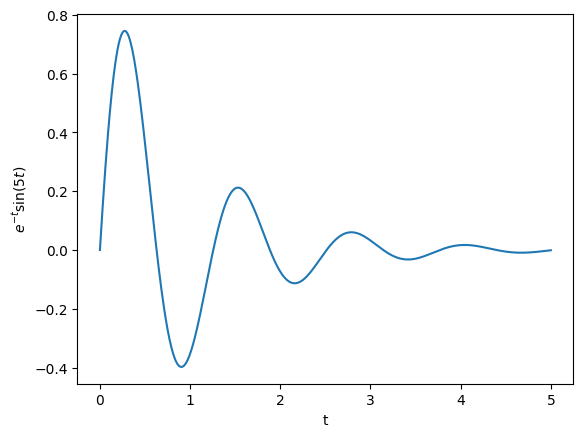

In [258]:
import numpy as np
import matplotlib.pyplot as plt

t = sym.Symbol('t')
expression = sym.exp(-t) * sym.sin(5 * t)     # une expression symbolique
fonction = sym.lambdify(t, expression, 'numpy')

tt = np.linspace(0, 5, 500)
plt.plot(tt, fonction(tt))
plt.xlabel("t"); plt.ylabel(r"$e^{-t}\sin(5t)$")
plt.show()

> **Exercice de synthèse : portée d'un projectile**
>
> 1. Avec SymPy, écrivez $x(t) = v_0 \cos\theta\, t$ et $y(t) = v_0 \sin\theta\, t - \tfrac12 g t^2$.
> 2. Trouvez l'instant $t_v$ du retour au sol ($y = 0$, $t > 0$) puis la portée $P = x(t_v)$ ; simplifiez : vous devriez retrouver $P = \dfrac{v_0^2 \sin 2\theta}{g}$.
> 3. Dérivez $P$ par rapport à $\theta$ et trouvez l'angle qui maximise la portée.
> 4. Avec `lambdify`, tracez $P(\theta)$ pour $v_0 = 20$ m/s.

Position horizontale x(t) :
t⋅v₀⋅cos(θ)

Position verticale y(t) :
     2              
  g⋅t               
- ──── + t⋅v₀⋅sin(θ)
   2                

Solutions de y(t) = 0 :
[2*v0*sin(theta)/g]

Temps total de vol :
2⋅v₀⋅sin(θ)
───────────
     g     

Portée simplifiée :
  2         
v₀ ⋅sin(2⋅θ)
────────────
     g      

Dérivée de la portée :
    2         
2⋅v₀ ⋅cos(2⋅θ)
──────────────
      g       

Angle optimal : pi/4
Angle optimal en degrés : 45°


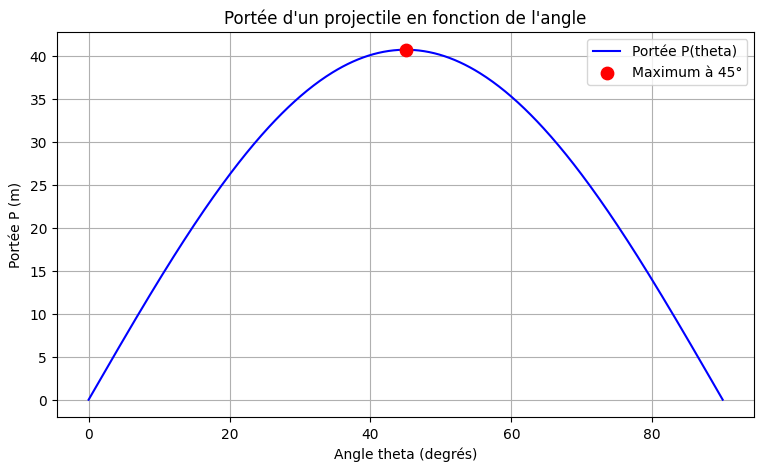


Portée maximale = 40.77 m


In [261]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. Équations symboliques du mouvement
# ==========================================

t, v0, theta, g = sp.symbols(
    't v0 theta g', real=True, positive=True
)

x = v0 * sp.cos(theta) * t
y = v0 * sp.sin(theta) * t - sp.Rational(1, 2) * g * t**2

print("Position horizontale x(t) :")
sp.pprint(x)

print("\nPosition verticale y(t) :")
sp.pprint(y)

# ==========================================
# 2. Temps de vol et portée
# ==========================================

solutions_t = sp.solve(y, t)

# Racine non nulle (retour au sol)
t_vol = 2 * v0 * sp.sin(theta) / g

P = sp.trigsimp(x.subs(t, t_vol))

print("\nSolutions de y(t) = 0 :")
print(solutions_t)

print("\nTemps total de vol :")
sp.pprint(t_vol)

print("\nPortée simplifiée :")
sp.pprint(P)

# ==========================================
# 3. Dérivée et angle optimal
# ==========================================

dP = sp.diff(P, theta)

print("\nDérivée de la portée :")
sp.pprint(sp.trigsimp(dP))

# Angle qui maximise la portée
theta_opt = sp.pi / 4

print("\nAngle optimal :", theta_opt)
print("Angle optimal en degrés : 45°")

# ==========================================
# 4. Graphique avec lambdify
# ==========================================

# Valeurs numériques
v0_val = 20
g_val = 9.81

# Transformer l'expression SymPy en fonction NumPy
P_fonction = sp.lambdify(
    theta,
    P.subs({v0: v0_val, g: g_val}),
    "numpy"
)

# Angles entre 0° et 90°
angles_deg = np.linspace(0, 90, 500)
angles_rad = np.deg2rad(angles_deg)

portees = P_fonction(angles_rad)

# Portée maximale
P_max = P_fonction(np.pi / 4)

# Tracé
plt.figure(figsize=(9, 5))

plt.plot(angles_deg, portees,
         label="Portée P(theta)", color="blue")

plt.scatter(45, P_max, color="red", s=80,
            label="Maximum à 45°", zorder=5)

plt.xlabel("Angle theta (degrés)")
plt.ylabel("Portée P (m)")
plt.title("Portée d'un projectile en fonction de l'angle")
plt.grid(True)
plt.legend()

plt.show()

print("\nPortée maximale =", round(P_max, 2), "m")

2⋅v₀⋅sin(θ)
───────────
     g     

  2         
v₀ ⋅sin(2⋅θ)
────────────
     g      

⎡π  3⋅π⎤
⎢─, ───⎥
⎣4   4 ⎦

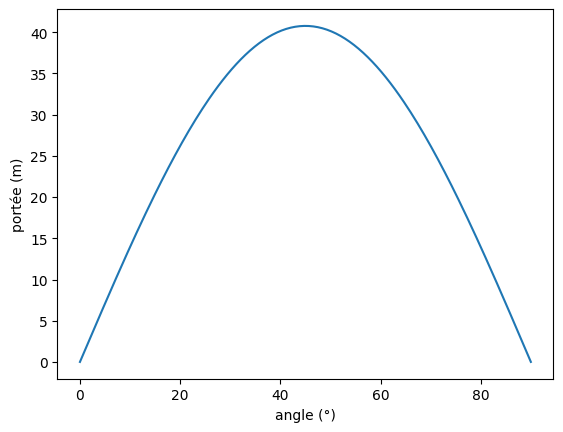

In [260]:
#@title Solution { display-mode: "form" }
t, v0, g = sym.symbols('t v_0 g', positive=True)
theta = sym.Symbol('theta', positive=True)

xt = v0 * sym.cos(theta) * t
yt = v0 * sym.sin(theta) * t - g * t**2 / 2

tv = sym.solve(yt, t)                 # solutions : t = 0 et t = 2 v0 sin(theta)/g
tv = [s for s in tv if s != 0][0]
P = sym.simplify(xt.subs(t, tv))
display(tv)
display(P)                            # v0^2 sin(2 theta)/g (sous forme équivalente)

dP = sym.diff(P, theta)
display(sym.solve(dP, theta))         # pi/4 : 45°

P_num = sym.lambdify(theta, P.subs({v0: 20, g: 9.81}), 'numpy')
ang = np.linspace(0, np.pi / 2, 200)
plt.plot(np.degrees(ang), P_num(ang))
plt.xlabel("angle (°)"); plt.ylabel("portée (m)")
plt.show()

# Pour aller plus loin

- La [documentation de SymPy](https://docs.sympy.org) et son [tutoriel](https://docs.sympy.org/latest/tutorials/intro-tutorial/index.html) (en anglais).
- Le sous-module `sympy.physics` : mécanique, optique, unités physiques, mécanique quantique…
- **SymPy Gamma / SymPy Live** : essayer SymPy en ligne.

---

*Fin du carnet 6. Vous avez maintenant les bases de Python scientifique pour la physique !*